In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt  
import seaborn as sns 
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error,mean_squared_error,r2_score
from scipy import stats


In [2]:
df_raw=pd.read_csv(r"C:\Users\HP\Desktop\Machine Learning 1\Project1_bike_Price\bikes.csv")

In [3]:
df_raw

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017,17000 Km,first owner,hyderabad,\n\n 35 kmpl,19 bhp,63500
1,Royal Enfield Classic 350cc 2016,2016,50000 Km,first owner,hyderabad,\n\n 35 kmpl,19.80 bhp,115000
2,Hyosung GT250R 2012,2012,14795 Km,first owner,hyderabad,\n\n 30 kmpl,28 bhp,300000
3,Bajaj Dominar 400 ABS 2017,2017,Mileage 28 Kms,first owner,pondicherry,\n\n 28 Kms,34.50 bhp,100000
4,Jawa Perak 330cc 2020,2020,2000 Km,first owner,bangalore,\n\n,30 bhp,197500
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011,7000 Km,first owner,agra,\n\n 42 kmpl,16 bhp,55000
7853,Bajaj Discover 100cc 2015,2015,Mileage 80 Kmpl,first owner,delhi,\n\n 80 Kmpl,7.7,28000
7854,Bajaj Pulsar 180cc 2016,2016,6407 Km,first owner,bangalore,\n\n 65 kmpl,17 bhp,61740
7855,Bajaj V15 150cc 2016,2016,7524 Km,first owner,bangalore,\n\n 57 kmpl,11.80 bhp,49000


In [4]:
df_raw['owner'].unique()

array(['first owner', 'third owner', 'second owner',
       'fourth owner or more'], dtype=object)

In [5]:
df_raw.dtypes

model_name    object
model_year     int64
kms_driven    object
owner         object
location      object
mileage       object
power         object
price          int64
dtype: object

In [6]:
df_raw.duplicated().sum 

<bound method Series.sum of 0       False
1       False
2       False
3       False
4       False
        ...  
7852    False
7853    False
7854    False
7855    False
7856    False
Length: 7857, dtype: bool>

In [7]:
df_raw.isnull().sum()

model_name     0
model_year     0
kms_driven     0
owner          0
location      19
mileage       11
power         31
price          0
dtype: int64

In [8]:
df_raw["price"].describe()

count    7.857000e+03
mean     1.067913e+05
std      1.389261e+05
min      0.000000e+00
25%      4.200000e+04
50%      7.500000e+04
75%      1.250000e+05
max      3.000000e+06
Name: price, dtype: float64

In [9]:
df_raw.columns

Index(['model_name', 'model_year', 'kms_driven', 'owner', 'location',
       'mileage', 'power', 'price'],
      dtype='object')

In [10]:
df_raw[['kms_driven','mileage','power']]

,kms_driven,mileage,power
0,17000 Km,\n\n 35 kmpl,19 bhp
1,50000 Km,\n\n 35 kmpl,19.80 bhp
2,14795 Km,\n\n 30 kmpl,28 bhp
3,Mileage 28 Kms,\n\n 28 Kms,34.50 bhp
4,2000 Km,\n\n,30 bhp
...,...,...,...
7852,7000 Km,\n\n 42 kmpl,16 bhp
7853,Mileage 80 Kmpl,\n\n 80 Kmpl,7.7
7854,6407 Km,\n\n 65 kmpl,17 bhp
7855,7524 Km,\n\n 57 kmpl,11.80 bhp


In [11]:
def get_number(value):
    if pd.isna(value):
        return np.nan

    value = str(value).replace(",","")
    number = ''
    dot_used = False

    for i in value:
        if i.isdigit():
            number += i
        elif i == '.' and not dot_used:
            number += i
            dot_used = True
        elif number:
            break

    return float(number) if number else np.nan

In [12]:
column_name=['mileage', 'power', 'price','model_year', 'kms_driven']
for i in column_name:
    df_raw[i]=df_raw[i].apply(get_number)

In [13]:
df_raw

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017.0,17000.0,first owner,hyderabad,35.0,19.0,63500.0
1,Royal Enfield Classic 350cc 2016,2016.0,50000.0,first owner,hyderabad,35.0,19.8,115000.0
2,Hyosung GT250R 2012,2012.0,14795.0,first owner,hyderabad,30.0,28.0,300000.0
3,Bajaj Dominar 400 ABS 2017,2017.0,28.0,first owner,pondicherry,28.0,34.5,100000.0
4,Jawa Perak 330cc 2020,2020.0,2000.0,first owner,bangalore,NaN,30.0,197500.0
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011.0,7000.0,first owner,agra,42.0,16.0,55000.0
7853,Bajaj Discover 100cc 2015,2015.0,80.0,first owner,delhi,80.0,7.7,28000.0
7854,Bajaj Pulsar 180cc 2016,2016.0,6407.0,first owner,bangalore,65.0,17.0,61740.0
7855,Bajaj V15 150cc 2016,2016.0,7524.0,first owner,bangalore,57.0,11.8,49000.0


In [14]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7857 entries, 0 to 7856
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   model_name  7857 non-null   object 
 1   model_year  7857 non-null   float64
 2   kms_driven  7854 non-null   float64
 3   owner       7857 non-null   object 
 4   location    7838 non-null   object 
 5   mileage     7083 non-null   float64
 6   power       7826 non-null   float64
 7   price       7857 non-null   float64
dtypes: float64(5), object(3)
memory usage: 491.2+ KB


In [15]:
df_raw.duplicated().sum()

0

In [16]:
df=df_raw.dropna(subset='price')

In [17]:
df

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017.0,17000.0,first owner,hyderabad,35.0,19.0,63500.0
1,Royal Enfield Classic 350cc 2016,2016.0,50000.0,first owner,hyderabad,35.0,19.8,115000.0
2,Hyosung GT250R 2012,2012.0,14795.0,first owner,hyderabad,30.0,28.0,300000.0
3,Bajaj Dominar 400 ABS 2017,2017.0,28.0,first owner,pondicherry,28.0,34.5,100000.0
4,Jawa Perak 330cc 2020,2020.0,2000.0,first owner,bangalore,NaN,30.0,197500.0
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011.0,7000.0,first owner,agra,42.0,16.0,55000.0
7853,Bajaj Discover 100cc 2015,2015.0,80.0,first owner,delhi,80.0,7.7,28000.0
7854,Bajaj Pulsar 180cc 2016,2016.0,6407.0,first owner,bangalore,65.0,17.0,61740.0
7855,Bajaj V15 150cc 2016,2016.0,7524.0,first owner,bangalore,57.0,11.8,49000.0


In [18]:
df[df['price']>0]

,model_name,model_year,kms_driven,owner,location,mileage,power,price
0,Bajaj Avenger Cruise 220 2017,2017.0,17000.0,first owner,hyderabad,35.0,19.0,63500.0
1,Royal Enfield Classic 350cc 2016,2016.0,50000.0,first owner,hyderabad,35.0,19.8,115000.0
2,Hyosung GT250R 2012,2012.0,14795.0,first owner,hyderabad,30.0,28.0,300000.0
3,Bajaj Dominar 400 ABS 2017,2017.0,28.0,first owner,pondicherry,28.0,34.5,100000.0
4,Jawa Perak 330cc 2020,2020.0,2000.0,first owner,bangalore,NaN,30.0,197500.0
...,...,...,...,...,...,...,...,...
7852,Yamaha YZF-R15 150cc 2011,2011.0,7000.0,first owner,agra,42.0,16.0,55000.0
7853,Bajaj Discover 100cc 2015,2015.0,80.0,first owner,delhi,80.0,7.7,28000.0
7854,Bajaj Pulsar 180cc 2016,2016.0,6407.0,first owner,bangalore,65.0,17.0,61740.0
7855,Bajaj V15 150cc 2016,2016.0,7524.0,first owner,bangalore,57.0,11.8,49000.0


In [19]:
df[df['model_year']<1990]

,model_name,model_year,kms_driven,owner,location,mileage,power,price
1691,Royal Enfield Bullet 350 cc 1982,1982.0,22000.0,first owner,pune,NaN,NaN,150000.0
1716,Royal Enfield Bullet 350 cc 1982,1982.0,16245.0,first owner,delhi,NaN,NaN,70000.0
2211,Bajaj Pulsar NS 200cc 2013,1950.0,35.0,first owner,noida,35.0,23.19,55000.0
2487,Royal Enfield Bullet 350 cc 1982,1982.0,3000.0,second owner,lalitpur,NaN,NaN,130000.0
2638,Ideal Jawa Yezdi Delux 250 cc 1978,1978.0,85000.0,first owner,chikamaglur,NaN,NaN,100000.0
2714,Royal Enfield Bullet 350 cc 1982,1982.0,21000.0,first owner,nashik,NaN,NaN,170000.0
3088,Royal Enfield Bullet 350 cc 1982,1982.0,10000.0,first owner,mumbai,NaN,NaN,60000.0
3429,Royal Enfield‎ Bullet 350cc 1970,1970.0,5000.0,third owner,pune,25.0,19.80,190000.0
4174,Royal Enfield Standard 350cc 1985,1985.0,40.0,third owner,kolhapur,40.0,18.00,125000.0
4258,Bajaj Pulsar NS 200cc 2013,1950.0,35.0,third owner,khalilabad,35.0,23.19,55000.0


In [20]:
pd.Timestamp.today().year

2026

In [21]:
if 'model_year' in df.columns:
    current_year=pd.Timestamp.today().year
    df['model_year']=df['model_year'].between(1998,current_year)

In [22]:
print(df)

                            model_name  model_year  kms_driven        owner  \
0        Bajaj Avenger Cruise 220 2017        True     17000.0  first owner   
1     Royal Enfield Classic 350cc 2016        True     50000.0  first owner   
2                  Hyosung GT250R 2012        True     14795.0  first owner   
3           Bajaj Dominar 400 ABS 2017        True        28.0  first owner   
4                Jawa Perak 330cc 2020        True      2000.0  first owner   
...                                ...         ...         ...          ...   
7852         Yamaha YZF-R15 150cc 2011        True      7000.0  first owner   
7853         Bajaj Discover 100cc 2015        True        80.0  first owner   
7854           Bajaj Pulsar 180cc 2016        True      6407.0  first owner   
7855              Bajaj V15 150cc 2016        True      7524.0  first owner   
7856           Bajaj Pulsar 220cc 2016        True     15000.0  first owner   

         location  mileage  power     price  
0    

In [23]:
df['location'].isnull()

0       False
1       False
2       False
3       False
4       False
        ...  
7852    False
7853    False
7854    False
7855    False
7856    False
Name: location, Length: 7857, dtype: bool

In [24]:
if 'model_year' in df.columns:
    current_year = pd.Timestamp.today().year
    df["bike_age"]=current_year-df["model_year"]

In [25]:
if "location" in df.columns:
    df["location"]=df["location"].fillna("unknown")

In [26]:
df_clean=df.copy()
df_clean.to_csv("bike__index=False")
print("Cleaned dataset saved as bike_cleaned.csv")
display(df_clean.head())

Cleaned dataset saved as bike_cleaned.csv


,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age
0,Bajaj Avenger Cruise 220 2017,True,17000.0,first owner,hyderabad,35.0,19.0,63500.0,2025
1,Royal Enfield Classic 350cc 2016,True,50000.0,first owner,hyderabad,35.0,19.8,115000.0,2025
2,Hyosung GT250R 2012,True,14795.0,first owner,hyderabad,30.0,28.0,300000.0,2025
3,Bajaj Dominar 400 ABS 2017,True,28.0,first owner,pondicherry,28.0,34.5,100000.0,2025
4,Jawa Perak 330cc 2020,True,2000.0,first owner,bangalore,NaN,30.0,197500.0,2025


In [27]:
df_clean["price"].describe()

count    7.857000e+03
mean     1.067913e+05
std      1.389261e+05
min      0.000000e+00
25%      4.200000e+04
50%      7.500000e+04
75%      1.250000e+05
max      3.000000e+06
Name: price, dtype: float64

In [28]:
df_clean["price"].skew()

6.212031912939482

<Axes: xlabel='price', ylabel='Count'>

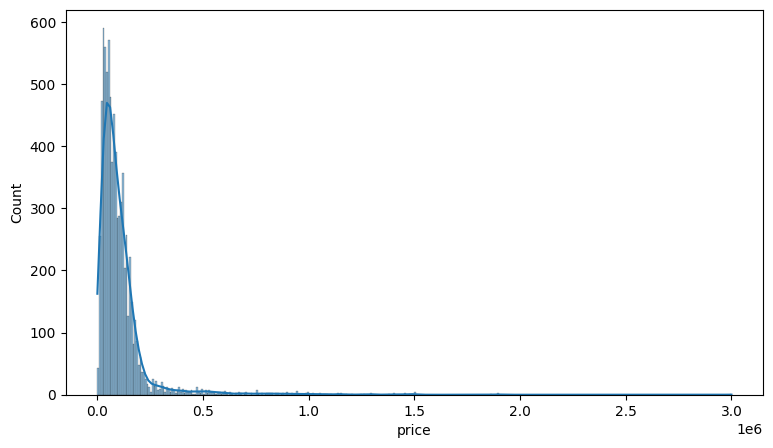

In [29]:
plt.figure(figsize=(9,5))
sns.histplot(data=df_clean,x='price',kde=True)

<Axes: xlabel='price'>

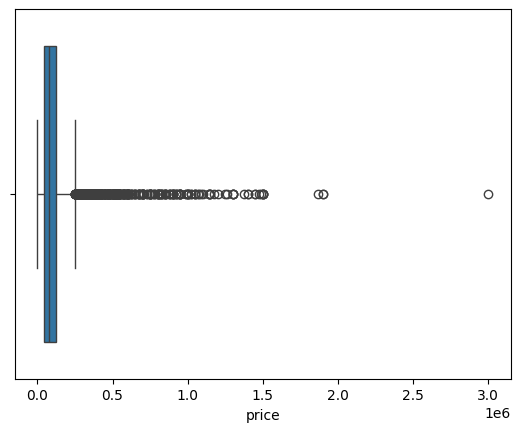

In [30]:
plt.Figure(figsize=(9,5))
sns.boxplot(data=df_clean,x='price')

In [31]:
df_clean['model_name'].str.split().str[0].str.lower()

0         bajaj
1         royal
2       hyosung
3         bajaj
4          jawa
         ...   
7852     yamaha
7853      bajaj
7854      bajaj
7855      bajaj
7856      bajaj
Name: model_name, Length: 7857, dtype: object

In [32]:
df_clean['brand']=df_clean['model_name'].str.split().str[0].str.lower()

In [33]:
df_clean['brand'].unique()

array(['bajaj', 'royal', 'hyosung', 'jawa', 'ktm', 'tvs', 'yamaha',
       'honda', 'um', 'hero', 'suzuki', 'husqvarna', 'mahindra',
       'harley-davidson', 'kawasaki', 'benelli', 'triumph', 'ducati',
       'bmw', 'ideal', 'benelliimperiale', 'moto', 'fb', 'indian',
       'yazdi', 'aprilia', 'mv'], dtype=object)

In [34]:
df_clean['brand'].str.lower().unique()

array(['bajaj', 'royal', 'hyosung', 'jawa', 'ktm', 'tvs', 'yamaha',
       'honda', 'um', 'hero', 'suzuki', 'husqvarna', 'mahindra',
       'harley-davidson', 'kawasaki', 'benelli', 'triumph', 'ducati',
       'bmw', 'ideal', 'benelliimperiale', 'moto', 'fb', 'indian',
       'yazdi', 'aprilia', 'mv'], dtype=object)

In [35]:
brand_stats=df_clean.groupby('brand')['price'].agg(['median','mean','count']).reset_index()

In [36]:
brand_stats

,brand,median,mean,count
0,aprilia,1000000.0,1.000000e+06,2
1,bajaj,50000.0,5.696317e+04,2105
2,benelli,260000.0,3.015819e+05,53
3,benelliimperiale,213750.0,2.169103e+05,6
4,bmw,274800.0,3.978600e+05,10
5,ducati,907293.5,9.762937e+05,16
6,fb,320850.0,3.208500e+05,2
7,harley-davidson,450000.0,5.127226e+05,171
8,hero,33000.0,3.819898e+04,808
9,honda,49749.5,7.090622e+04,530


In [37]:
brand_top_10=brand_stats[brand_stats['count']>10].sort_values(by='median',ascending=False).head(10)

In [38]:
brand_top_10

,brand,median,mean,count
5,ducati,907293.5,976293.687500,16
22,triumph,800000.0,843183.250000,36
15,kawasaki,465000.0,496517.701493,67
7,harley-davidson,450000.0,512722.602339,171
2,benelli,260000.0,301581.886792,53
10,husqvarna,205000.0,206767.000000,11
11,hyosung,193600.0,213450.555556,54
14,jawa,165000.0,171286.130435,46
16,ktm,147000.0,150354.556008,491
24,um,125000.0,128446.007812,128


<Axes: xlabel='brand', ylabel='median'>

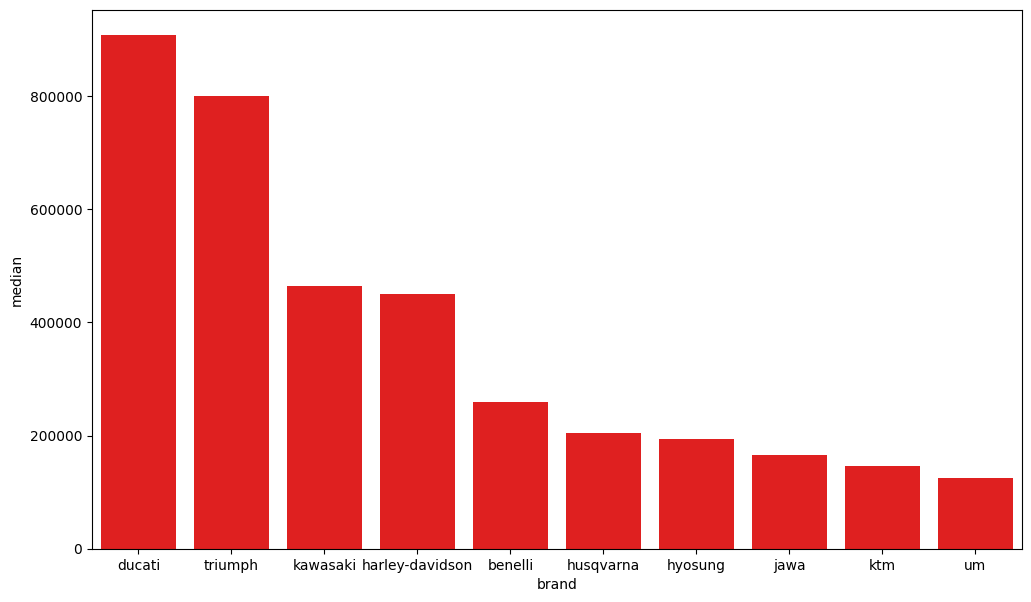

In [39]:
plt.figure(figsize=(12,7))
sns.barplot(data=brand_top_10,x='brand',y='median',color='red')

In [40]:
df_clean[['kms_driven','price']].corr()

,kms_driven,price
kms_driven,1.000000,-0.114032
price,-0.114032,1.000000


In [41]:
plot_data=df_clean.dropna(subset=['kms_driven','price'])
if len(plot_data)>3000:
    plot_data=plot_data.sample(3000,random_state=42)

<Axes: xlabel='kms_driven', ylabel='price'>

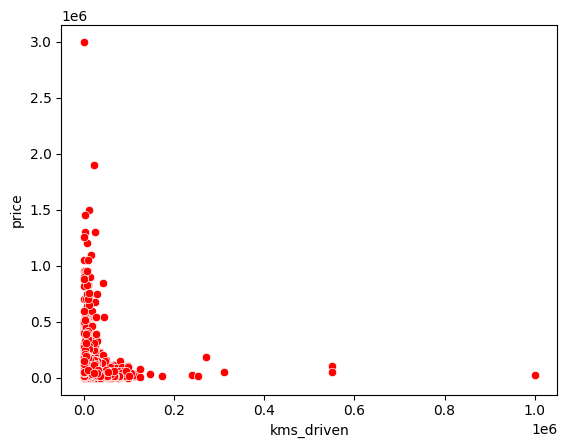

In [42]:
plt.Figure(figsize=(10,4))
sns.scatterplot(data=plot_data,x='kms_driven',y='price',color='red')

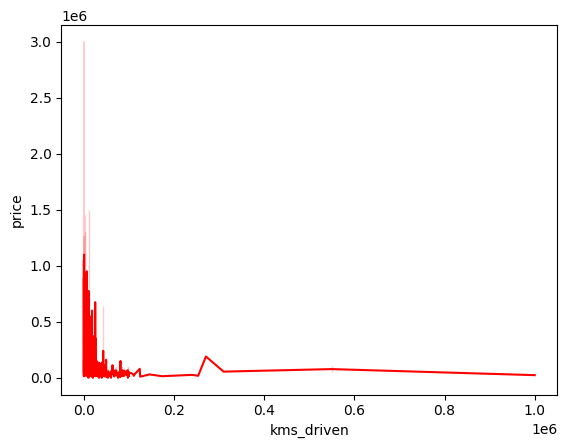

In [43]:
# plt.lineplot(data=plot_data,x='kms_driven',y='price',color='red')

sns.lineplot(data=plot_data, x='kms_driven', y='price', color='red')

plt.show()

<Axes: xlabel='bike_age', ylabel='price'>

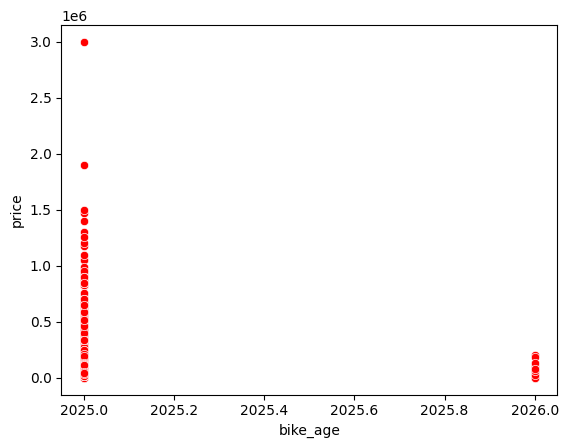

In [44]:
plot_data=df_clean.dropna(subset=['bike_age','price'])
if len(plot_data)>3000:
    plot_data=plot_data.sample(3000,random_state=42)
    plt.Figure(figsize=(10,4))
sns.scatterplot(data=plot_data,x='bike_age',y='price',color='red')

<Axes: >

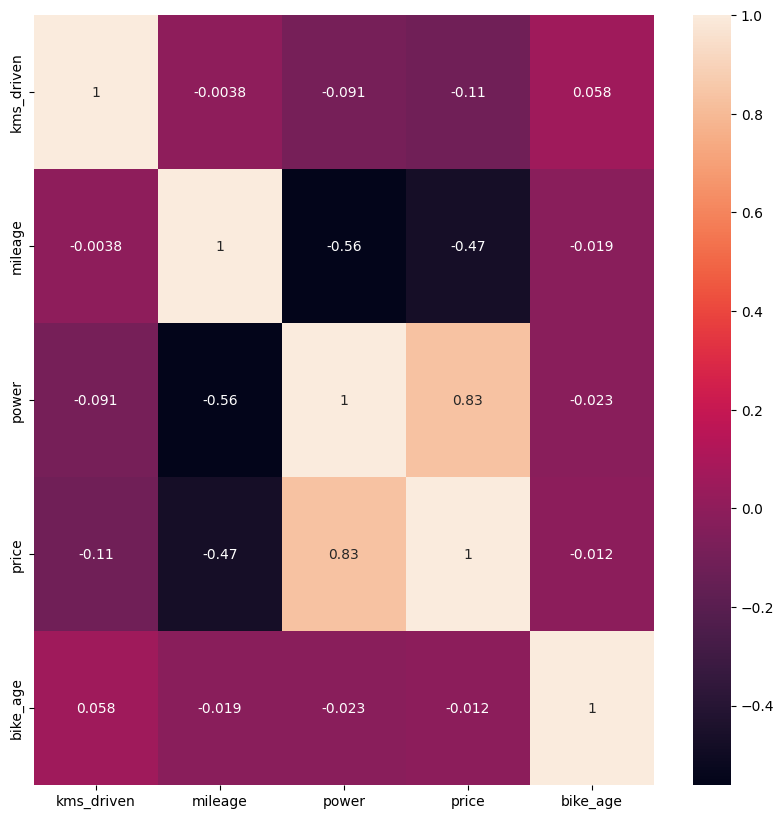

In [45]:
numeric_df=df_clean.select_dtypes(include='number')
plt.figure(figsize=(10,10))
sns.heatmap(numeric_df.corr(),annot=True)

In [46]:
df_clean.dropna(inplace=True)

In [47]:
df_clean.reset_index(inplace=True,drop='first')

In [48]:
df_clean

,model_name,model_year,kms_driven,owner,location,mileage,power,price,bike_age,brand
0,Bajaj Avenger Cruise 220 2017,True,17000.0,first owner,hyderabad,35.0,19.0,63500.0,2025,bajaj
1,Royal Enfield Classic 350cc 2016,True,50000.0,first owner,hyderabad,35.0,19.8,115000.0,2025,royal
2,Hyosung GT250R 2012,True,14795.0,first owner,hyderabad,30.0,28.0,300000.0,2025,hyosung
3,Bajaj Dominar 400 ABS 2017,True,28.0,first owner,pondicherry,28.0,34.5,100000.0,2025,bajaj
4,KTM Duke 200cc 2012,True,24561.0,third owner,bangalore,35.0,25.0,63400.0,2025,ktm
...,...,...,...,...,...,...,...,...,...,...
7071,Yamaha YZF-R15 150cc 2011,True,7000.0,first owner,agra,42.0,16.0,55000.0,2025,yamaha
7072,Bajaj Discover 100cc 2015,True,80.0,first owner,delhi,80.0,7.7,28000.0,2025,bajaj
7073,Bajaj Pulsar 180cc 2016,True,6407.0,first owner,bangalore,65.0,17.0,61740.0,2025,bajaj
7074,Bajaj V15 150cc 2016,True,7524.0,first owner,bangalore,57.0,11.8,49000.0,2025,bajaj


In [49]:
df_clean.drop(['model_name','location'],axis=1)

,model_year,kms_driven,owner,mileage,power,price,bike_age,brand
0,True,17000.0,first owner,35.0,19.0,63500.0,2025,bajaj
1,True,50000.0,first owner,35.0,19.8,115000.0,2025,royal
2,True,14795.0,first owner,30.0,28.0,300000.0,2025,hyosung
3,True,28.0,first owner,28.0,34.5,100000.0,2025,bajaj
4,True,24561.0,third owner,35.0,25.0,63400.0,2025,ktm
...,...,...,...,...,...,...,...,...
7071,True,7000.0,first owner,42.0,16.0,55000.0,2025,yamaha
7072,True,80.0,first owner,80.0,7.7,28000.0,2025,bajaj
7073,True,6407.0,first owner,65.0,17.0,61740.0,2025,bajaj
7074,True,7524.0,first owner,57.0,11.8,49000.0,2025,bajaj


In [50]:
data=df_clean.drop(['model_name','location'],axis=1)

In [51]:
data.columns

Index(['model_year', 'kms_driven', 'owner', 'mileage', 'power', 'price',
       'bike_age', 'brand'],
      dtype='object')

In [52]:
x=data[['model_year', 'kms_driven', 'owner', 'mileage', 'power','bike_age', 'brand']]
y=data['price']

In [53]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.2)

In [54]:

numerical_column=x.select_dtypes(include='number').columns.tolist()
categorical_column=x.select_dtypes(exclude='number').columns.tolist()



In [55]:
numeric_pipeline=Pipeline(steps=[('imputer',SimpleImputer(strategy='median'))])
categorical_pipeline=Pipeline(steps=[('imputer',SimpleImputer(strategy='most_frequent')),
('ohe',OneHotEncoder(handle_unknown='ignore'))])


In [57]:
transformers =[]
if numerical_column:
    transformers.append(("numeric",numeric_pipeline,numerical_column))
if categorical_column:
    transformers.append(("categorical",categorical_pipeline,categorical_column))
    
preprocessor=ColumnTransformer(transformers=transformers)

model=Pipeline(steps=[('preprocessor',preprocessor),
("regression",LinearRegression())
])
model.fit(x,y)
print("Linear Regression model trained")

Linear Regression model trained


In [58]:
y_pred=model.predict(x_test)
comparison=pd.DataFrame({
"actual_price":y_test.values,
"predicted_price":np.round(y_pred,0),
"error_actual_minus_predicted":np.round(y_test.values-y_pred,0)
})

comparison["absolute_error"]=comparison["error_actual_minus_predicted"].abs()
display(comparison.head(15))

,actual_price,predicted_price,error_actual_minus_predicted,absolute_error
0,25000.0,52298.0,-27298.0,27298.0
1,300000.0,465160.0,-165160.0,165160.0
2,15000.0,26077.0,-11077.0,11077.0
3,197125.0,115242.0,81883.0,81883.0
4,105000.0,114205.0,-9205.0,9205.0
5,85000.0,59425.0,25575.0,25575.0
6,19300.0,14483.0,4817.0,4817.0
7,50000.0,73615.0,-23615.0,23615.0
8,112999.0,62774.0,50225.0,50225.0
9,18500.0,-3743.0,22243.0,22243.0


In [59]:
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("MAE: ${:,.0f}".format(mae))
print("MSE: ${:,.0f}".format(mse))
print("RMSE: ${:,.0f}".format(rmse))
print("R2: {:.3f}".format(r2))


MAE: $32,207
MSE: $3,222,416,095
RMSE: $56,766
R2: 0.834


Text(0.5, 1.0, 'Actual vs Predicted Bike Price')

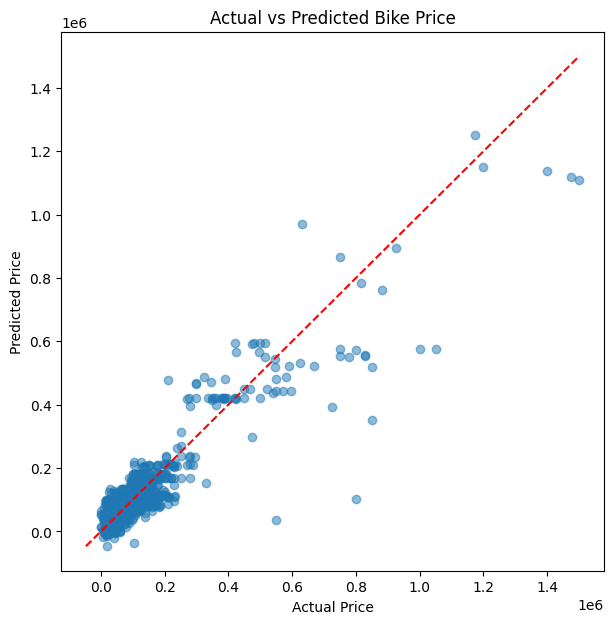

In [60]:
plt.figure(figsize=(7,7))
plt.scatter(y_test,y_pred,alpha=0.5)
min_value=min(y_test.min(),y_pred.min())
max_value=max(y_test.max(),y_pred.max())
plt.plot([min_value,max_value],[min_value,max_value],"r--")
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Bike Price")

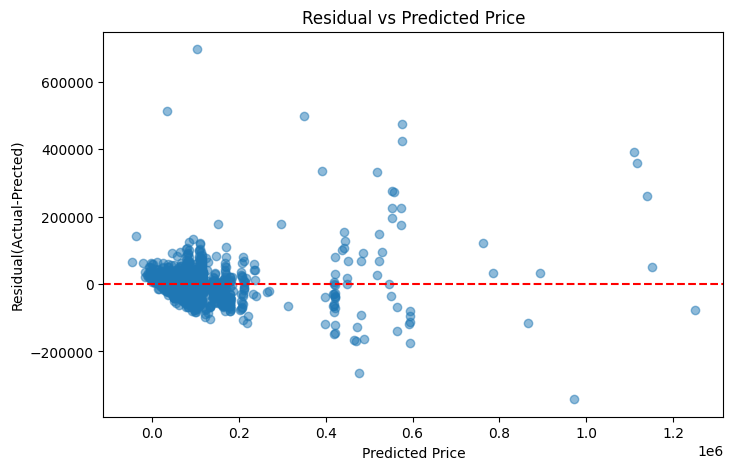

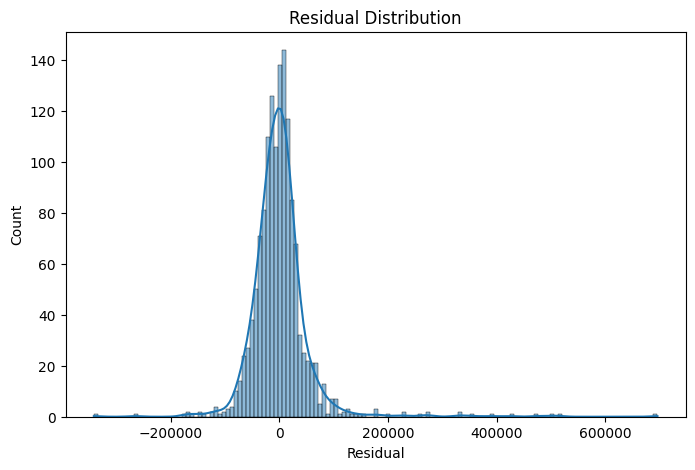

Mean residual: 741.79


In [61]:
residuals=y_test-y_pred

plt.figure(figsize=(8,5))
plt.scatter(y_pred,residuals,alpha=0.5)
plt.axhline(0,color="red",linestyle="--")
plt.xlabel("Predicted Price")
plt.ylabel("Residual(Actual-Prected)")
plt.title("Residual vs Predicted Price")
plt.show()
plt.figure(figsize=(8,5))
sns.histplot(residuals,kde=True)
plt.title("Residual Distribution")
plt.xlabel("Residual")
plt.show()
print("Mean residual:",round(residuals.mean(),2))